<a href="https://colab.research.google.com/github/rfroiman/DI_Bootcamp/blob/main/Week8/Day3/Exercises_XP_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercises XP: Text Preprocessing, NER, POS, and Word2Vec

Use this guided notebook to follow the platform instructions step by step. Prefilled cells are ready to run; cells marked TODO expect your code or analysis.

## What you will learn
- Clean and normalize raw reviews with tokenization, stopword removal, and lemmatization.
- Extract linguistic features with named entity recognition (NER) and part-of-speech (POS) tagging.
- Train a simple Word2Vec model and interpret its vector dimensions.
- Visualize word embeddings to reason about semantic neighborhoods.

## What you will create
- A `preprocess_text` function that lowercases, strips punctuation, removes stopwords, and lemmatizes.
- `perform_ner` and `perform_pos_tagging` helpers to analyze raw vs cleaned text.
- A Word2Vec model plus a helper to plot embeddings for inspection.

> Learning point
> Run the setup cells once, then progress through each exercise sequentially. Print intermediate results to verify every helper works before moving on.

## Setup · install libraries
Run once to install spaCy, nltk, gensim, and plotting utilities.

In [ ]:
%pip install --quiet spacy nltk gensim matplotlib seaborn --upgrade

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 54.9 MB/s eta 0:00:00


In [ ]:
import nltk
import spacy
from spacy.cli import download as spacy_download

# Allow NLTK downloads through the trusted Colab proxy
nltk.pathsec.ALLOW_PROXIED_FETCH = True

resources = [
    "punkt",
    "punkt_tab",
    "wordnet",
    "omw-1.4",
    "stopwords",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "tagsets",
]

for res in resources:
    nltk.download(res, quiet=True)

nlp = spacy.load("en_core_web_sm")

print("spaCy pipeline:", nlp.pipe_names)
print("NLTK resources downloaded successfully.")

spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
NLTK resources downloaded successfully.


## Exercise 1 · Explore text preprocessing, NER, and POS tags

Here is the dataset you will reuse in every step.

In [3]:
data = {
    'Review': [
        "At McDonald's the food was ok and the service was bad.",
        "I would not recommend this Japanese restaurant to anyone.",
        "I loved this restaurant when I traveled to Thailand last summer.",
        "The menu of Loving has a wide variety of options.",
        "The staff was friendly and helpful at Google's employees restaurant.",
        "The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",
        "I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.",
        "The sushi at Sushi Express is always fresh and flavorful.",
        "The steakhouse on Main Street has a cozy atmosphere and excellent steaks.",
        "The dessert selection at Sweet Treats is to die for!"
    ]
}
raw_reviews = data['Review']
raw_reviews


["At McDonald's the food was ok and the service was bad.",
 'I would not recommend this Japanese restaurant to anyone.',
 'I loved this restaurant when I traveled to Thailand last summer.',
 'The menu of Loving has a wide variety of options.',
 "The staff was friendly and helpful at Google's employees restaurant.",
 'The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.',
 'I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.',
 'The sushi at Sushi Express is always fresh and flavorful.',
 'The steakhouse on Main Street has a cozy atmosphere and excellent steaks.',
 'The dessert selection at Sweet Treats is to die for!']

### 1.1 Build `preprocess_text()`
Create a function that:
1. Lowercases and tokenizes text.
2. Removes punctuation tokens.
3. Removes English stopwords.
4. Applies a lemmatizer.
5. Returns the cleaned string joined by spaces.

Print the processed reviews to confirm every stage works.

In [4]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text: str) -> str:
    """Lowercase, tokenize, remove punctuation and stopwords, and lemmatize."""

    text = text.lower()

    tokens = nltk.word_tokenize(text)

    tokens = [
        token for token in tokens
        if token not in string.punctuation
        and token.isalpha()
    ]

    tokens = [
        token for token in tokens
        if token not in stop_words
    ]

    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
    ]

    return " ".join(tokens)


# Test the function
print("Original:", raw_reviews[0])
print("Cleaned:", preprocess_text(raw_reviews[0]))

Original: At McDonald's the food was ok and the service was bad.
Cleaned: mcdonald food ok service bad


### 1.2 Create a cleaned dataset
Apply `preprocess_text` to every review and keep both raw and cleaned versions side by side.

In [5]:
# Create a cleaned dataset while preserving the original reviews
cleaned_reviews = [
    preprocess_text(review)
    for review in raw_reviews
]

# Compare original and cleaned reviews
for raw, cleaned in zip(raw_reviews, cleaned_reviews):
    print(f"RAW: {raw}")
    print(f"CLEANED: {cleaned}\n")

print("Total cleaned reviews:", len(cleaned_reviews))

RAW: At McDonald's the food was ok and the service was bad.
CLEANED: mcdonald food ok service bad

RAW: I would not recommend this Japanese restaurant to anyone.
CLEANED: would recommend japanese restaurant anyone

RAW: I loved this restaurant when I traveled to Thailand last summer.
CLEANED: loved restaurant traveled thailand last summer

RAW: The menu of Loving has a wide variety of options.
CLEANED: menu loving wide variety option

RAW: The staff was friendly and helpful at Google's employees restaurant.
CLEANED: staff friendly helpful google employee restaurant

RAW: The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.
CLEANED: ambiance bella italia amazing pasta dish delicious

RAW: I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.
CLEANED: terrible experience pizza hut pizza burnt service slow

RAW: The sushi at Sushi Express is always fresh and flavorful.
CLEANED: sushi sushi express always fresh flavorful

RAW: The 

### 1.3 Named Entity Recognition (NER)
Create `perform_ner(text)` that returns `(entity, label_)` pairs using `en_core_web_sm`. Test it on a few reviews.

In [ ]:
def perform_ner(text: str):
    """Return named entities and their labels using spaCy."""
    doc = nlp(text)

    entities = [
        (entity.text, entity.label_)
        for entity in doc.ents
    ]

    return entities


# Test NER on the first three original reviews
for review in raw_reviews[:3]:
    print("Review:", review)
    print("Entities:", perform_ner(review))
    print()

Review: At McDonald's the food was ok and the service was bad.
Entities: [('McDonald', 'ORG')]

Review: I would not recommend this Japanese restaurant to anyone.
Entities: [('Japanese', 'NORP')]

Review: I loved this restaurant when I traveled to Thailand last summer.
Entities: [('Thailand', 'GPE'), ('last summer', 'DATE')]



### 1.4 Part-of-Speech tagging (POS)
Create `perform_pos_tagging(text)` using `nltk.pos_tag`. Test it on both raw and cleaned text.

Use `nltk.help.upenn_tagset('NN')` to recall tag meanings if needed.

In [ ]:
from nltk import pos_tag, word_tokenize

def perform_pos_tagging(text: str):
    """Return POS tags for a given text."""
    tokens = word_tokenize(text)
    return pos_tag(tokens)


# Test POS tagging on the first review
print("Original review:")
print(raw_reviews[0])

print("\nPOS tags:")
print(perform_pos_tagging(raw_reviews[0]))

Original review:
At McDonald's the food was ok and the service was bad.

POS tags:
[('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]


### 1.5 Apply NER and POS on raw vs cleaned text
Compare outputs on the same entries to see how preprocessing affects tagging.

In [ ]:
sample_texts = raw_reviews[:2]
sample_cleaned = cleaned_reviews[:2]

print("NER on raw text")
for text in sample_texts:
    print(perform_ner(text))

print("\nNER on cleaned text")
for text in sample_cleaned:
    print(perform_ner(text))

print("\nPOS tags on raw text")
for text in sample_texts:
    print(perform_pos_tagging(text))

print("\nPOS tags on cleaned text")
for text in sample_cleaned:
    print(perform_pos_tagging(text))

NER on raw text
[('McDonald', 'ORG')]
[('Japanese', 'NORP')]

NER on cleaned text
[('mcdonald food ok service', 'ORG')]
[('japanese', 'NORP')]

POS tags on raw text
[('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]
[('I', 'PRP'), ('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('this', 'DT'), ('Japanese', 'JJ'), ('restaurant', 'NN'), ('to', 'TO'), ('anyone', 'NN'), ('.', '.')]

POS tags on cleaned text
[('mcdonald', 'NNS'), ('food', 'NN'), ('ok', 'JJ'), ('service', 'NN'), ('bad', 'JJ')]
[('would', 'MD'), ('recommend', 'VB'), ('japanese', 'JJ'), ('restaurant', 'NN'), ('anyone', 'NN')]


### Exercise 1 — Analysis

The preprocessing function successfully removed punctuation and stopwords, converted text to lowercase, and applied lemmatization.

NER performed better on raw text because the original capitalization and sentence structure helped identify entities correctly. For example, "McDonald" was recognized as an organization, while the cleaned text incorrectly grouped "mcdonald food ok service" as one organization.

POS tagging also changed after preprocessing. In the raw text, "McDonald" was identified as a proper noun (NNP), while the cleaned version classified "mcdonald" as a plural noun (NNS).

Removing stopwords can also change the meaning of a sentence. For example, "would not recommend" became "would recommend" because the word "not" was removed.

Overall, raw text is generally more suitable for NER and POS tagging, while cleaned text can be useful for word frequency analysis and Word2Vec.

## Exercise 2 · Plotting word embeddings

### 2.1 Train a Word2Vec model
Vectorize the preprocessed/tokenized dataset with `Word2Vec` from `gensim.models`. Reuse the cleaned text and adjust parameters like `vector_size`, `window`, and `sg`.

In [6]:
from gensim.models import Word2Vec

# Tokenize the preprocessed reviews
tokenized_reviews = [
    review.split()
    for review in cleaned_reviews
]

# Train the Word2Vec model
w2v_model = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=100
)

print("Word2Vec model trained successfully!")
print("Total reviews:", len(tokenized_reviews))
print("Vocabulary size:", len(w2v_model.wv))

Word2Vec model trained successfully!
Total reviews: 10
Vocabulary size: 55


### 2.2 Inspect embedding dimensions
Print and interpret the vector size and vocabulary size from the fitted model.

In [ ]:
# Inspect Word2Vec dimensions and vocabulary
print("Vector dimensions:", w2v_model.vector_size)
print("Vocabulary size:", len(w2v_model.wv))
print("Word vector shape:", w2v_model.wv["restaurant"].shape)


Vector dimensions: 100
Vocabulary size: 55
Word vector shape: (100,)


### Exercise 2.2 — Analysis

The Word2Vec model was trained using 10 preprocessed restaurant reviews.

The vocabulary contains 55 unique words, and each word is represented by a vector of 100 numerical dimensions.

These dimensions are learned features that help represent relationships between words based on their surrounding context.

The shape (100,) confirms that each word has a one-dimensional array containing 100 values.

Since the dataset contains only 10 short reviews, the model has limited training data and may not learn reliable semantic relationships.

### 2.3 Plot word embeddings
Complete `plot_word_embeddings(model)` to scatter-plot the first two dimensions of the learned vectors and annotate each point with its word. Discuss whether related words cluster together.

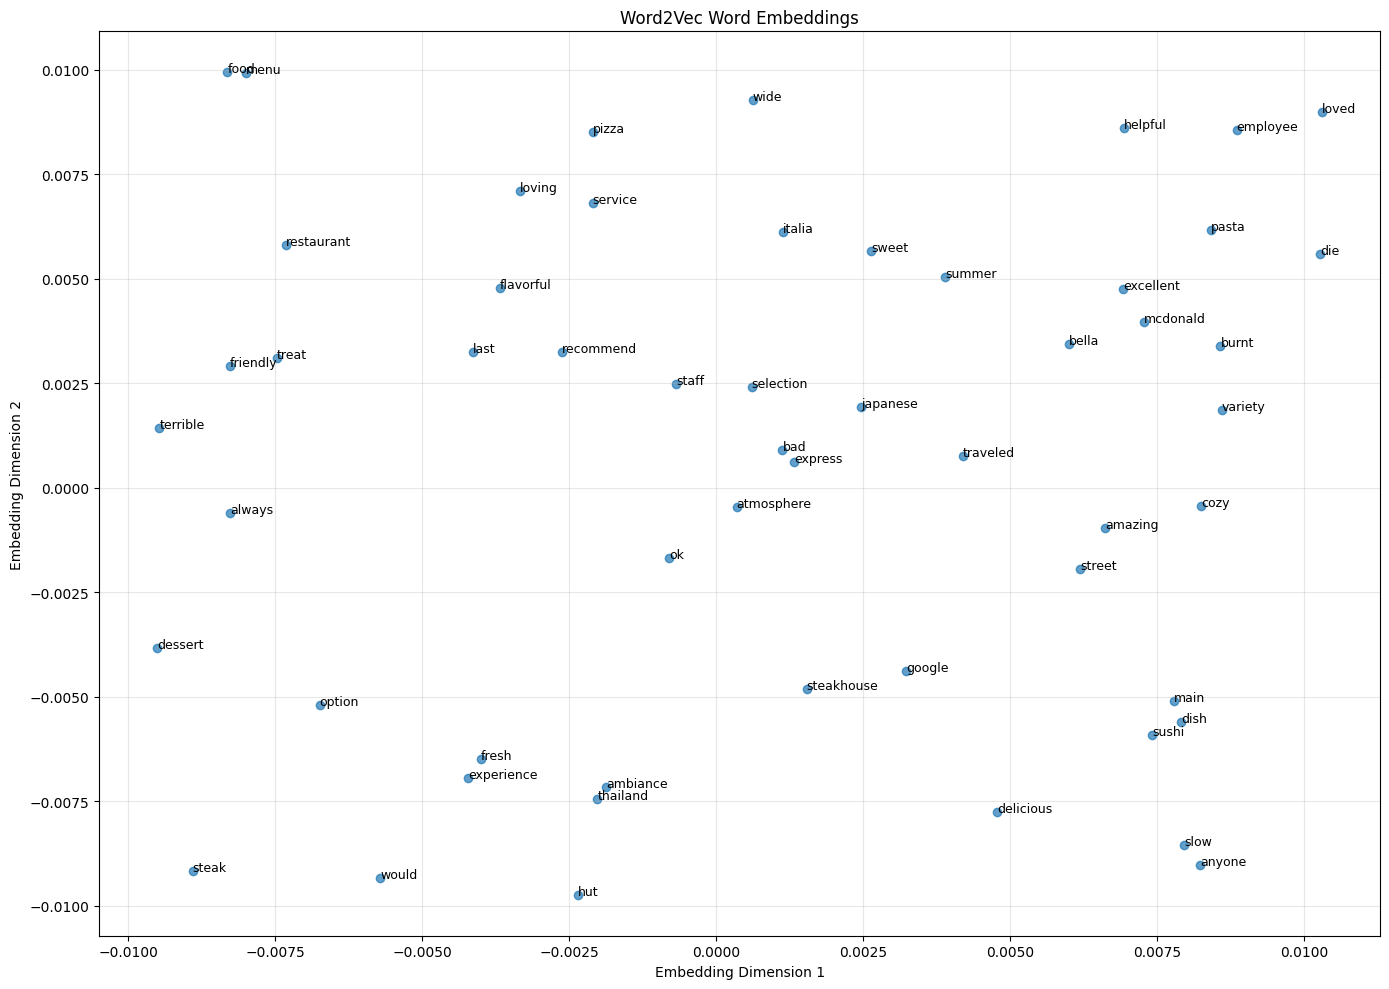

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_word_embeddings(model, words=None):
    """Plot the first two dimensions of Word2Vec embeddings."""

    if words is None:
        words = model.wv.index_to_key

    vectors = np.array([model.wv[word] for word in words])

    plt.figure(figsize=(14, 10))

    plt.scatter(vectors[:, 0], vectors[:, 1], alpha=0.7)

    for i, word in enumerate(words):
        plt.annotate(
            word,
            (vectors[i, 0], vectors[i, 1]),
            fontsize=9
        )

    plt.title("Word2Vec Word Embeddings")
    plt.xlabel("Embedding Dimension 1")
    plt.ylabel("Embedding Dimension 2")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# Plot the embeddings
plot_word_embeddings(w2v_model)

### Exercise 2.3 — Analysis

The scatter plot displays the first two dimensions of the Word2Vec embeddings, with each point representing a word.

Related words do not necessarily appear close together in this visualization.

One possible reason is the small dataset, which contains only 10 reviews and provides limited context for learning semantic relationships.

Another reason is that the original embeddings have 100 dimensions, while the plot displays only the first two. Important relationships may exist in the remaining dimensions.

A larger dataset and dimensionality reduction techniques such as PCA or t-SNE could improve the visualization.

### 2.4 Go further
- Experiment with different preprocessing (e.g., bigrams, stemming vs lemmatization).
- Tune Word2Vec hyperparameters and compare the plots.
- Try dimensionality reduction (PCA/t-SNE) for richer visualizations.

In [7]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Get all word vectors
words = w2v_model.wv.index_to_key
vectors = np.array([w2v_model.wv[word] for word in words])

# Reduce embeddings from 100 to 2 dimensions
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(vectors)

# Plot PCA embeddings
plt.figure(figsize=(14, 10))
plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], alpha=0.7)

for i, word in enumerate(words):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=9)

plt.title("Word2Vec Embeddings with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("word2vec_pca.png", dpi=150, bbox_inches="tight")
plt.close()

print("Original dimensions:", vectors.shape)
print("PCA dimensions:", reduced_vectors.shape)

Original dimensions: (55, 100)
PCA dimensions: (55, 2)


### Exercise 2.4 — PCA Analysis

The original Word2Vec model contains 55 word vectors, each with 100 dimensions.

PCA successfully reduced the embeddings from (55, 100) to (55, 2), making them easier to visualize.

Unlike plotting the first two dimensions directly, PCA creates two new dimensions that preserve as much variance as possible.

However, the dataset contains only 10 reviews, so the learned semantic relationships may still be limited.

Using a larger dataset and experimenting with Word2Vec parameters could improve the quality of the embeddings.